
# 08 — Horizon File Audit and Model Comparison

This notebook is for the multi-horizon thesis experiments. It follows the same file structure used in `07_Secondary_Safety_Evaluation.ipynb`, but repeats the file audit and metric extraction for every horizon.

It does four things:

1. Finds the prediction files for each model and each horizon.
2. Tells which files should be kept, checked, or optionally archived.
3. Computes global and regime metrics from the prediction files.
4. Produces comparison plots for the same models across horizons.

The horizons are **1, 15, 25, 50, 75, and 125 frames**. The 15-frame horizon is used instead of 13.


In [71]:

# ============================================================
# IMPORTS
# ============================================================

from pathlib import Path
import json
import gc
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)


In [72]:

# ============================================================
# CONFIG — EDIT ONLY THIS CELL IF YOUR FOLDERS CHANGE
# ============================================================

PROJECT_DIR = Path(
    r"C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility"
)

DATA_DIR = PROJECT_DIR / "processed_data_final"
OUTPUT_DIR = DATA_DIR / "horizon_file_audit_and_model_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Main asymmetric setting
BRAKE_THRESHOLD = -0.1
ACCEL_THRESHOLD = 0.2
THRESHOLD_TAG = "brake0p1_accel0p2"
IDM_PARAM_TAG = "refinedIDM_v2"

FPS = 25
HISTORY = 25
STRIDE = 1

# IMPORTANT: 15 frames is used instead of 13 frames
HORIZONS = [1, 15, 25, 50, 75, 125]
HORIZON_LABELS = {h: f"{h / FPS:.2f}s" for h in HORIZONS}

# If True, row counts are computed for every discovered prediction file.
# For very large files this can take time, but it is useful for checking fair comparisons.
COUNT_ROWS = True

print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("Horizons:", HORIZONS)
print("Horizon labels:", HORIZON_LABELS)

assert DATA_DIR.exists(), f"DATA_DIR does not exist: {DATA_DIR}"


DATA_DIR: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final
OUTPUT_DIR: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison
Horizons: [1, 15, 25, 50, 75, 125]
Horizon labels: {1: '0.04s', 15: '0.60s', 25: '1.00s', 50: '2.00s', 75: '3.00s', 125: '5.00s'}


In [73]:

# ============================================================
# MODEL DEFINITIONS
# ============================================================

MODEL_SPECS = [
    {"Model": "Global IDM", "Family": "IDM", "Type": "Deployable", "RootKey": "idm_core", "FileName": "global_idm_test_predictions.csv", "FileTokens": ["global", "idm", "test", "predictions"]},
    {"Model": "True-regime IDM", "Family": "IDM", "Type": "Upper-bound", "RootKey": "idm_core", "FileName": "oracle_regime_aware_idm_test_predictions.csv", "FileTokens": ["oracle", "regime", "aware", "idm", "test", "predictions"], "AlternativeTokens": [["true", "regime", "idm", "test", "predictions"]]},
    {"Model": "Ideal best-candidate IDM", "Family": "IDM", "Type": "Upper-bound", "RootKey": "idm_core", "FileName": "ideal_best_candidate_idm_test_predictions.csv", "FileTokens": ["ideal", "best", "candidate", "idm", "test", "predictions"]},
    {"Model": "XGB-soft best-IDM selector","Family": "IDM","Type": "Deployable","RootKey": "idm_selector","FileName": "xgb_soft_best_idm_test_predictions.csv","FileTokens": ["xgb", "idm", "predictions"], "AlternativeTokens": [
        ["xgb", "best", "idm", "predictions"], ["xgb", "soft", "idm", "predictions"], ["xgb", "best", "idm", "test"], ["best", "idm", "selector", "predictions"], ["xgb", "selector", "predictions"],],},
    {"Model": "Plain Transformer", "Family": "Transformer", "Type": "Deployable", "RootKey": "transformer_baseline", "FolderPrefix": "transformer_baseline", "FileName": "transformer_test_predictions.csv", "FileTokens": ["transformer", "test", "predictions"]},
    {"Model": "Residual Hybrid + Global IDM", "Family": "IDM-first hybrid", "Type": "Deployable", "RootKey": "hybrid_idm_first", "FolderPrefix": "Hybrid_GlobalIDM", "FileName": "test_predictions.csv", "FileTokens": ["test", "predictions"]},
    {"Model": "Residual Hybrid + True-regime IDM", "Family": "IDM-first hybrid", "Type": "Upper-bound", "RootKey": "hybrid_idm_first", "FolderPrefix": "Hybrid_OracleRegimeAwareIDM", "AltFolderPrefixes": ["Hybrid_TrueRegimeAwareIDM"], "FileName": "test_predictions.csv", "FileTokens": ["test", "predictions"]},
    {"Model": "Residual Hybrid + Tree-selected IDM", "Family": "IDM-first hybrid", "Type": "Deployable", "RootKey": "hybrid_idm_first", "FolderPrefix": "Hybrid_TreeRegimeAwareIDM", "FileName": "test_predictions.csv", "FileTokens": ["test", "predictions"]},
    {"Model": "Residual Hybrid + XGB-soft best-IDM", "Family": "IDM-first hybrid", "Type": "Deployable", "RootKey": "hybrid_idm_first", "FolderPrefix": "Hybrid_XGBSoftBestIDM", "FileName": "test_predictions.csv", "FileTokens": ["test", "predictions"]},
    {"Model": "Transformer Weighted Fusion + Global IDM", "Family": "Transformer-based hybrid", "Type": "Deployable", "RootKey": "weighted_fusion", "FolderPrefix": "TransformerWeightedFusion_GlobalIDM", "FileName": "weighted_fusion_test_predictions.csv", "FileTokens": ["weighted", "fusion", "test", "predictions"]},
    {"Model": "Transformer Weighted Fusion + True-regime IDM", "Family": "Transformer-based hybrid", "Type": "Upper-bound", "RootKey": "weighted_fusion", "FolderPrefix": "TransformerWeightedFusion_IdealRegimeAwareIDM", "AltFolderPrefixes": ["TransformerWeightedFusion_TrueRegimeAwareIDM", "TransformerWeightedFusion_OracleRegimeAwareIDM"], "FileName": "weighted_fusion_test_predictions.csv", "FileTokens": ["weighted", "fusion", "test", "predictions"]},
    {"Model": "Transformer Weighted Fusion + Tree-selected IDM", "Family": "Transformer-based hybrid", "Type": "Deployable", "RootKey": "weighted_fusion", "FolderPrefix": "TransformerWeightedFusion_TreeRegimeAwareIDM", "FileName": "weighted_fusion_test_predictions.csv", "FileTokens": ["weighted", "fusion", "test", "predictions"]},
    {"Model": "Transformer + XGB-soft best-IDM feature", "Family": "Transformer-based hybrid", "Type": "Deployable", "RootKey": "transformer_idm_feature", "FolderPrefix": "TransformerIDMFeature_XGBSoftBestIDM", "FileName": "transformer_xgb_soft_best_idm_feature_test_predictions.csv", "FileTokens": ["transformer", "xgb", "soft", "best", "idm", "feature", "test", "predictions"]},
]

ROOTS = {
    "idm_core": DATA_DIR / "idm_core_runs" / f"idm_core_{THRESHOLD_TAG}",
    "idm_selector": DATA_DIR / "idm_selector_comparison_runs" / f"idm_selector_comparison_{THRESHOLD_TAG}",
    "transformer_baseline": DATA_DIR / "transformer_baseline_runs",
    "hybrid_idm_first": DATA_DIR / "hybrid_idm_first_runs",
    "weighted_fusion": DATA_DIR / "transformer_weighted_fusion_runs",
    "transformer_idm_feature": DATA_DIR / "transformer_idm_feature_runs",
}

for key, root in ROOTS.items():
    print(f"{key}: {root} | exists={root.exists()}")


idm_core: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_brake0p1_accel0p2 | exists=True
idm_selector: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_selector_comparison_runs\idm_selector_comparison_brake0p1_accel0p2 | exists=True
transformer_baseline: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs | exists=True
hybrid_idm_first: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\hybrid_idm_first_runs | exists=True
weighted_fusion: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_weighted_fusion_runs | exists=True
transformer_idm_feature: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_idm_feature_runs | exists=True


In [74]:

# ============================================================
# FILE DISCOVERY HELPERS
# ============================================================

def horizon_tag(h):
    return f"H{HISTORY}_Hz{h}_S{STRIDE}"


def legacy_idm_first_tag(h):
    # Old one-step IDM-first runs sometimes used H25_S1 instead of H25_Hz1_S1.
    if h == 1:
        return f"H{HISTORY}_S{STRIDE}"
    return horizon_tag(h)


def safe_stat(path):
    try:
        st = path.stat()
        return {"size_mb": st.st_size / (1024 ** 2), "modified_time": datetime.fromtimestamp(st.st_mtime)}
    except Exception:
        return {"size_mb": np.nan, "modified_time": pd.NaT}


def fast_count_csv_rows(path):
    if not COUNT_ROWS:
        return np.nan
    try:
        with open(path, "rb") as f:
            return max(sum(1 for _ in f) - 1, 0)
    except Exception:
        return np.nan


def name_has_tokens(name, tokens):
    low = name.lower()
    return all(tok.lower() in low for tok in tokens)


def path_score(path, h):
    s = str(path).lower()
    tag = horizon_tag(h).lower()
    legacy_tag = legacy_idm_first_tag(h).lower()
    score = 0
    if tag in s:
        score += 1000
    if h == 1 and legacy_tag in s:
        score += 800
    if THRESHOLD_TAG.lower() in s:
        score += 200
    if IDM_PARAM_TAG.lower() in s:
        score += 100
    for preferred in ["currentstateprior", "futurealigned", "baselinematched", "v2"]:
        if preferred in s:
            score += 20
    if "old" in s or "backup" in s or "cópia" in s or "copy" in s:
        score -= 200
    try:
        score += path.stat().st_mtime / 1e10
    except Exception:
        pass
    return score


def exact_candidates_for_spec(spec, h):
    tag = horizon_tag(h)
    root = ROOTS[spec["RootKey"]]
    candidates = []

    if spec["RootKey"] in ["idm_core", "idm_selector"]:
        fname = spec["FileName"]
        stem = Path(fname).stem
        suffix = Path(fname).suffix
        candidates.extend([
            root / f"{stem}_{tag}{suffix}",
            root / f"{tag}_{fname}",
            root / tag / fname,
        ])
        if h == 1:
            candidates.append(root / fname)
    else:
        prefixes = [spec.get("FolderPrefix")] + spec.get("AltFolderPrefixes", [])
        prefixes = [p for p in prefixes if p]
        for prefix in prefixes:
            candidates.append(root / f"{prefix}_{tag}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}" / spec["FileName"])
            candidates.append(root / f"{prefix}_{tag}_{THRESHOLD_TAG}" / spec["FileName"])
            if root.exists():
                for folder in root.glob(f"{prefix}_{tag}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}*"):
                    candidates.append(folder / spec["FileName"])
            if spec["RootKey"] == "hybrid_idm_first" and h == 1:
                legacy = legacy_idm_first_tag(h)
                candidates.append(root / f"{prefix}_{legacy}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}" / spec["FileName"])
    return candidates


def broad_candidates_for_spec(spec, h):
    root = ROOTS[spec["RootKey"]]
    tag = horizon_tag(h).lower()
    legacy = legacy_idm_first_tag(h).lower()

    found = []

    # --------------------------------------------------------
    # Special robust search for XGB-soft best-IDM selector
    # --------------------------------------------------------
    if spec["Model"] == "XGB-soft best-IDM selector":

        # Search wider than ROOTS["idm_selector"], because these files
        # may be saved directly in horizon-specific selector folders.
        search_roots = [
            root,
            DATA_DIR / "idm_selector_comparison_runs",
            DATA_DIR,
        ]

        seen_roots = []
        for r in search_roots:
            if r.exists() and r not in seen_roots:
                seen_roots.append(r)

        for search_root in seen_roots:
            for path in search_root.rglob("*.csv"):
                low_path = str(path).lower()
                low_name = path.name.lower()

                # Must be the XGB-soft selector prediction file
                is_selector_prediction = (
                    low_name.startswith("xgb_soft_best_idm_test_predictions")
                    or low_name.startswith("xgb_best_idm_soft_test_predictions")
                    or low_name.startswith("xgb_soft_best_idm_predictions")
                    or low_name.startswith("xgb_best_idm_soft_predictions")
                )

                if not is_selector_prediction:
                    continue

                # Horizon must match
                if h > 1 and tag not in low_path:
                    continue

                if h == 1 and tag not in low_path and legacy not in low_path:
                    # allow old untagged 0.04s file
                    if "h25_hz" in low_path or "h25_s" in low_path:
                        continue

                found.append(path)

        return found

    # --------------------------------------------------------
    # Generic search for all other models
    # --------------------------------------------------------
    if not root.exists():
        return []

    token_sets = [spec.get("FileTokens", [])] + spec.get("AlternativeTokens", [])

    for path in root.rglob("*.csv"):
        low_path = str(path).lower()
        low_name = path.name.lower()

        if h > 1 and tag not in low_path:
            continue

        if h == 1 and tag not in low_path and legacy not in low_path:
            if spec["RootKey"] not in ["idm_core", "idm_selector"]:
                continue

        if not any(name_has_tokens(low_name, token_set) for token_set in token_sets):
            continue

        prefixes = [spec.get("FolderPrefix")] + spec.get("AltFolderPrefixes", [])
        prefixes = [p.lower() for p in prefixes if p]

        if prefixes and not any(p in low_path for p in prefixes):
            continue

        

        found.append(path)

    return found


def discover_prediction_file(spec, h):
    candidates = [p for p in exact_candidates_for_spec(spec, h) if p.exists()]
    candidates.extend(broad_candidates_for_spec(spec, h))
    candidates = list(dict.fromkeys(candidates))

    if len(candidates) == 0:
        return None, []

    ranked = sorted(candidates, key=lambda p: path_score(p, h), reverse=True)
    return ranked[0], ranked


In [75]:

# ============================================================
# BUILD FILE AUDIT / KEEP MANIFEST
# ============================================================

manifest_rows = []
extra_rows = []

for h in HORIZONS:
    tag = horizon_tag(h)
    for spec in MODEL_SPECS:
        chosen, candidates = discover_prediction_file(spec, h)

        if chosen is None:
            manifest_rows.append({
                "HorizonFrames": h,
                "HorizonSeconds": h / FPS,
                "HorizonLabel": HORIZON_LABELS[h],
                "HorizonTag": tag,
                "Model": spec["Model"],
                "Family": spec["Family"],
                "Type": spec["Type"],
                "Status": "MISSING",
                "Action": "CHECK: run missing or filename pattern not recognized",
                "PredictionFile": None,
                "CandidateCount": 0,
                "Rows": np.nan,
                "SizeMB": np.nan,
                "ModifiedTime": pd.NaT,
            })
            continue

        stat = safe_stat(chosen)
        manifest_rows.append({
            "HorizonFrames": h,
            "HorizonSeconds": h / FPS,
            "HorizonLabel": HORIZON_LABELS[h],
            "HorizonTag": tag,
            "Model": spec["Model"],
            "Family": spec["Family"],
            "Type": spec["Type"],
            "Status": "FOUND",
            "Action": "KEEP: selected prediction file for tables/plots",
            "PredictionFile": str(chosen),
            "CandidateCount": len(candidates),
            "Rows": fast_count_csv_rows(chosen),
            "SizeMB": stat["size_mb"],
            "ModifiedTime": stat["modified_time"],
        })

        for alt in candidates[1:]:
            stat_alt = safe_stat(alt)
            extra_rows.append({
                "HorizonFrames": h,
                "HorizonSeconds": h / FPS,
                "HorizonLabel": HORIZON_LABELS[h],
                "HorizonTag": tag,
                "Model": spec["Model"],
                "Family": spec["Family"],
                "Type": spec["Type"],
                "Status": "DUPLICATE_CANDIDATE",
                "Action": "ARCHIVE_OPTIONAL: duplicate candidate; selected file is in main manifest",
                "PredictionFile": str(alt),
                "CandidateCount": len(candidates),
                "Rows": np.nan,
                "SizeMB": stat_alt["size_mb"],
                "ModifiedTime": stat_alt["modified_time"],
            })

file_manifest_df = pd.DataFrame(manifest_rows)
extra_candidates_df = pd.DataFrame(extra_rows)

print("Main manifest shape:", file_manifest_df.shape)
print("Extra candidates shape:", extra_candidates_df.shape)

print("Status counts:")
display(file_manifest_df["Status"].value_counts(dropna=False).to_frame("count"))

print("Missing files:")
display(
    file_manifest_df[file_manifest_df["Status"] == "MISSING"]
    .sort_values(["HorizonFrames", "Family", "Model"])
    [["HorizonLabel", "HorizonTag", "Model", "Family", "Type", "Action"]]
)

print("Found files:")
display(
    file_manifest_df[file_manifest_df["Status"] == "FOUND"]
    .sort_values(["HorizonFrames", "Family", "Model"])
    [["HorizonLabel", "Model", "Rows", "SizeMB", "ModifiedTime", "PredictionFile"]]
)


Main manifest shape: (78, 14)
Extra candidates shape: (49, 14)
Status counts:


,count
Status,
FOUND,78


Missing files:


,HorizonLabel,HorizonTag,Model,Family,Type,Action


Found files:


,HorizonLabel,Model,Rows,SizeMB,ModifiedTime,PredictionFile
0,0.04s,Global IDM,1628545,307.909078,2026-06-27 12:26:39.763475,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
2,0.04s,Ideal best-candidate IDM,1628545,396.849297,2026-06-27 12:27:43.190536,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
1,0.04s,True-regime IDM,1628545,358.223551,2026-06-27 12:27:19.121439,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
3,0.04s,XGB-soft best-IDM selector,2368174,1347.003610,2026-06-07 02:07:50.063896,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
5,0.04s,Residual Hybrid + Global IDM,2188870,491.577508,2026-06-07 16:05:22.553653,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
...,...,...,...,...,...,...
69,5.00s,Plain Transformer,1257619,108.825214,2026-06-16 02:02:23.911971,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
77,5.00s,Transformer + XGB-soft best-IDM feature,1257619,352.960152,2026-06-21 15:39:12.743316,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
74,5.00s,Transformer Weighted Fusion + Global IDM,1257619,296.896044,2026-06-17 22:41:09.297791,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
76,5.00s,Transformer Weighted Fusion + Tree-selected IDM,1257619,336.989048,2026-06-17 23:07:59.320311,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...


In [76]:

# ============================================================
# FAIRNESS CHECK: ARE MODELS USING THE SAME NUMBER OF TEST ROWS?
# ============================================================

row_check = (
    file_manifest_df[file_manifest_df["Status"] == "FOUND"]
    .groupby(["HorizonFrames", "HorizonLabel"], as_index=False)
    .agg(
        models_found=("Model", "nunique"),
        min_rows=("Rows", "min"),
        max_rows=("Rows", "max"),
        unique_row_counts=("Rows", lambda s: sorted(pd.Series(s).dropna().unique().tolist())[:10]),
    )
)
row_check["same_row_count"] = row_check["min_rows"] == row_check["max_rows"]

display(row_check)

print("Note: if same_row_count is False, the models may not be evaluated on exactly the same samples.")
print("For final thesis comparison, prefer corrected horizon-aligned prediction files with matching test counts.")


,HorizonFrames,HorizonLabel,models_found,min_rows,max_rows,unique_row_counts,same_row_count
0,1,0.04s,13,1628545,2368174,"[1628545, 2181399, 2188870, 2368174]",False
1,15,0.60s,13,2076805,2256109,"[2076805, 2256109]",False
2,25,1.00s,13,2002095,2181399,"[2002095, 2181399]",False
3,50,2.00s,13,1815320,1994624,"[1815320, 1994624]",False
4,75,3.00s,13,1628545,1807849,"[1628545, 1807849]",False
5,125,5.00s,13,1257619,1434299,"[1257619, 1434299]",False


Note: if same_row_count is False, the models may not be evaluated on exactly the same samples.
For final thesis comparison, prefer corrected horizon-aligned prediction files with matching test counts.


In [77]:

# ============================================================
# METRIC HELPERS
# ============================================================

POSSIBLE_USEFUL_COLS = [
    "y_true", "y_pred",
    "a_true", "target", "true_accel",
    "prediction", "a_pred", "pred", "test_pred", "y_hat",
    "a_idm", "a_idm_prior", "a_idm_piecewise", "a_idm_best_candidate", "a_idm_soft", "a_hybrid",
    "weighted_pred", "fusion_pred", "final_pred",
    "gap", "v_ego", "v_leader", "delta_v",
    "episode_id", "unique_id", "frame", "split",
]


def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    err = y_pred - y_true
    abs_err = np.abs(err)
    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return {
        "MAE": np.mean(abs_err),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MedAE": np.median(abs_err),
        "R2": 1 - ss_res / ss_tot if ss_tot > 0 else np.nan,
        "Bias": np.mean(err),
        "Corr": np.corrcoef(y_true, y_pred)[0, 1] if np.std(y_true) > 0 and np.std(y_pred) > 0 else np.nan,
        "Count": len(y_true),
    }


def load_prediction_minimal(path):
    header = pd.read_csv(path, nrows=0).columns.tolist()
    usecols = [c for c in POSSIBLE_USEFUL_COLS if c in header]
    if len(usecols) == 0:
        raise ValueError(f"No useful columns found in {path}. Header: {header}")
    dtype_map = {}
    for c in usecols:
        if c not in ["episode_id", "unique_id", "split"]:
            dtype_map[c] = "float32" if c != "frame" else "int32"
    return pd.read_csv(path, usecols=usecols, dtype=dtype_map, low_memory=False)


def standardize_prediction_columns(df, model_name):
    out = df.copy()

    if "y_true" not in out.columns:
        for c in ["a_true", "target", "true_accel"]:
            if c in out.columns:
                out["y_true"] = out[c].astype(np.float32)
                break

    if "y_pred" not in out.columns:
        for c in [
            "prediction", "a_pred", "pred", "test_pred", "y_hat",
            "a_idm", "a_idm_prior", "a_idm_piecewise", "a_idm_best_candidate", "a_idm_soft", "a_hybrid",
            "weighted_pred", "fusion_pred", "final_pred",
        ]:
            if c in out.columns:
                out["y_pred"] = out[c].astype(np.float32)
                break

    if "y_true" not in out.columns or "y_pred" not in out.columns:
        raise ValueError(f"Could not identify y_true/y_pred for {model_name}. Columns: {list(out.columns)}")

    keep = ["y_true", "y_pred"]
    for c in ["gap", "v_ego", "v_leader", "delta_v", "episode_id", "unique_id", "frame", "split"]:
        if c in out.columns:
            keep.append(c)
    out = out[keep].copy().dropna(subset=["y_true", "y_pred"])

    out["error"] = out["y_pred"] - out["y_true"]
    out["abs_error"] = out["error"].abs()
    out["regime"] = np.select(
        [out["y_true"] < BRAKE_THRESHOLD, out["y_true"] > ACCEL_THRESHOLD],
        ["braking", "accelerating"],
        default="steady",
    )
    out["Model"] = model_name
    return out


In [78]:

# ============================================================
# COMPUTE GLOBAL AND REGIME METRICS FROM FOUND FILES
# ============================================================

global_rows = []
regime_rows = []
load_errors = []

found_manifest = file_manifest_df[file_manifest_df["Status"] == "FOUND"].copy()

for _, row in found_manifest.iterrows():
    path = Path(row["PredictionFile"])
    model = row["Model"]
    h = int(row["HorizonFrames"])
    try:
        raw = load_prediction_minimal(path)
        pred_df = standardize_prediction_columns(raw, model)

        metrics = compute_metrics(pred_df["y_true"], pred_df["y_pred"])
        metrics.update({
            "HorizonFrames": h,
            "HorizonSeconds": h / FPS,
            "HorizonLabel": row["HorizonLabel"],
            "HorizonTag": row["HorizonTag"],
            "Model": model,
            "Family": row["Family"],
            "Type": row["Type"],
            "PredictionFile": row["PredictionFile"],
        })
        global_rows.append(metrics)

        for regime, g in pred_df.groupby("regime", sort=False):
            m = compute_metrics(g["y_true"], g["y_pred"])
            m.update({
                "HorizonFrames": h,
                "HorizonSeconds": h / FPS,
                "HorizonLabel": row["HorizonLabel"],
                "HorizonTag": row["HorizonTag"],
                "Model": model,
                "Family": row["Family"],
                "Type": row["Type"],
                "Regime": regime,
                "PredictionFile": row["PredictionFile"],
            })
            regime_rows.append(m)

        del raw, pred_df
        gc.collect()
    except Exception as e:
        load_errors.append({
            "HorizonFrames": h,
            "Model": model,
            "PredictionFile": row["PredictionFile"],
            "Error": repr(e),
        })
        print(f"ERROR loading {model} | {row['HorizonLabel']}: {e}")

global_metrics_df = pd.DataFrame(global_rows)
regime_metrics_df = pd.DataFrame(regime_rows)
load_errors_df = pd.DataFrame(load_errors)

print("Global metrics:", global_metrics_df.shape)
print("Regime metrics:", regime_metrics_df.shape)
print("Load errors:", load_errors_df.shape)

display(global_metrics_df.sort_values(["HorizonFrames", "MAE"])[["HorizonLabel", "Model", "Type", "Family", "MAE", "RMSE", "MedAE", "R2", "Bias", "Corr", "Count"]])

if len(load_errors_df) > 0:
    display(load_errors_df)


Global metrics: (78, 15)
Regime metrics: (234, 16)
Load errors: (0, 0)


,HorizonLabel,Model,Type,Family,MAE,RMSE,MedAE,R2,Bias,Corr,Count
6,0.04s,Residual Hybrid + True-regime IDM,Upper-bound,IDM-first hybrid,0.095641,0.134914,0.077226,0.831229,-0.026739,0.915465,2188870
2,0.04s,Ideal best-candidate IDM,Upper-bound,IDM,0.110659,0.213225,0.064893,0.599666,0.004456,0.791359,1628545
10,0.04s,Transformer Weighted Fusion + True-regime IDM,Upper-bound,Transformer-based hybrid,0.110662,0.211377,0.061161,0.586167,0.000186,0.804954,2181399
1,0.04s,True-regime IDM,Upper-bound,IDM,0.126943,0.226956,0.082287,0.546446,0.017777,0.749740,1628545
4,0.04s,Plain Transformer,Deployable,Transformer,0.143432,0.265859,0.071500,0.345347,-0.002777,0.589217,2181399
...,...,...,...,...,...,...,...,...,...,...,...
72,5.00s,Residual Hybrid + Tree-selected IDM,Deployable,IDM-first hybrid,0.212742,0.325917,0.138533,0.082525,-0.010013,0.288784,1257619
70,5.00s,Residual Hybrid + Global IDM,Deployable,IDM-first hybrid,0.214798,0.327261,0.141302,0.074941,-0.005759,0.274452,1257619
73,5.00s,Residual Hybrid + XGB-soft best-IDM,Deployable,IDM-first hybrid,0.215134,0.328295,0.141408,0.069086,-0.032569,0.279951,1257619
68,5.00s,XGB-soft best-IDM selector,Deployable,IDM,0.216863,0.333856,0.138491,0.029537,0.005665,0.173600,1434299


In [79]:

# ============================================================
# COMPLETENESS TABLE: WHICH MODELS HAVE ALL HORIZONS?
# ============================================================

availability = (
    file_manifest_df
    .assign(Available=lambda d: d["Status"].eq("FOUND"))
    .pivot_table(index=["Model", "Family", "Type"], columns="HorizonLabel", values="Available", aggfunc="max", fill_value=False)
)
ordered_cols = [HORIZON_LABELS[h] for h in HORIZONS]
availability = availability.reindex(columns=ordered_cols)
availability["AvailableCount"] = availability[ordered_cols].sum(axis=1)
availability["Complete"] = availability["AvailableCount"].eq(len(HORIZONS))

display(availability.reset_index())

complete_models = availability[availability["Complete"]].reset_index()["Model"].tolist()
print("Models complete for all horizons:")
for m in complete_models:
    print("-", m)


HorizonLabel,Model,Family,Type,0.04s,0.60s,1.00s,2.00s,3.00s,5.00s,AvailableCount,Complete
0,Global IDM,IDM,Deployable,True,True,True,True,True,True,6,True
1,Ideal best-candidate IDM,IDM,Upper-bound,True,True,True,True,True,True,6,True
2,Plain Transformer,Transformer,Deployable,True,True,True,True,True,True,6,True
3,Residual Hybrid + Global IDM,IDM-first hybrid,Deployable,True,True,True,True,True,True,6,True
4,Residual Hybrid + Tree-selected IDM,IDM-first hybrid,Deployable,True,True,True,True,True,True,6,True
5,Residual Hybrid + True-regime IDM,IDM-first hybrid,Upper-bound,True,True,True,True,True,True,6,True
6,Residual Hybrid + XGB-soft best-IDM,IDM-first hybrid,Deployable,True,True,True,True,True,True,6,True
7,Transformer + XGB-soft best-IDM feature,Transformer-based hybrid,Deployable,True,True,True,True,True,True,6,True
8,Transformer Weighted Fusion + Global IDM,Transformer-based hybrid,Deployable,True,True,True,True,True,True,6,True
9,Transformer Weighted Fusion + Tree-selected IDM,Transformer-based hybrid,Deployable,True,True,True,True,True,True,6,True


Models complete for all horizons:
- Global IDM
- Ideal best-candidate IDM
- Plain Transformer
- Residual Hybrid + Global IDM
- Residual Hybrid + Tree-selected IDM
- Residual Hybrid + True-regime IDM
- Residual Hybrid + XGB-soft best-IDM
- Transformer + XGB-soft best-IDM feature
- Transformer Weighted Fusion + Global IDM
- Transformer Weighted Fusion + Tree-selected IDM
- Transformer Weighted Fusion + True-regime IDM
- True-regime IDM
- XGB-soft best-IDM selector


In [80]:

# ============================================================
# TABLES FOR THESIS / DECISION MAKING
# ============================================================

best_deployable = (
    global_metrics_df[global_metrics_df["Type"] == "Deployable"]
    .sort_values(["HorizonFrames", "MAE"])
    .groupby("HorizonFrames", as_index=False)
    .first()
)

best_upper = (
    global_metrics_df[global_metrics_df["Type"] == "Upper-bound"]
    .sort_values(["HorizonFrames", "MAE"])
    .groupby("HorizonFrames", as_index=False)
    .first()
)

print("Best deployable model per horizon:")
display(best_deployable[["HorizonLabel", "Model", "MAE", "RMSE", "R2", "Count"]])

print("Best upper-bound model per horizon:")
display(best_upper[["HorizonLabel", "Model", "MAE", "RMSE", "R2", "Count"]])

mae_wide = global_metrics_df.pivot_table(index=["Model", "Family", "Type"], columns="HorizonLabel", values="MAE", aggfunc="first").reindex(columns=ordered_cols)
print("Global MAE by model and horizon:")
display(mae_wide.reset_index())


Best deployable model per horizon:


,HorizonLabel,Model,MAE,RMSE,R2,Count
0,0.04s,Plain Transformer,0.143432,0.265859,0.345347,2181399
1,0.60s,Transformer + XGB-soft best-IDM feature,0.152359,0.276761,0.301130,2076805
2,1.00s,Transformer + XGB-soft best-IDM feature,0.157683,0.279464,0.293981,2002095
3,2.00s,Plain Transformer,0.177969,0.292647,0.237606,1815320
4,3.00s,Plain Transformer,0.185319,0.297150,0.222506,1628545
5,5.00s,Transformer Weighted Fusion + Tree-selected IDM,0.200829,0.314677,0.144714,1257619


Best upper-bound model per horizon:


,HorizonLabel,Model,MAE,RMSE,R2,Count
0,0.04s,Residual Hybrid + True-regime IDM,0.095641,0.134914,0.831229,2188870
1,0.60s,Residual Hybrid + True-regime IDM,0.101928,0.160201,0.765837,2076805
2,1.00s,Residual Hybrid + True-regime IDM,0.106659,0.171318,0.734680,2002095
3,2.00s,Residual Hybrid + True-regime IDM,0.097130,0.160995,0.769262,1815320
4,3.00s,Residual Hybrid + True-regime IDM,0.097044,0.175376,0.729176,1628545
5,5.00s,Residual Hybrid + True-regime IDM,0.102445,0.186249,0.700382,1257619


Global MAE by model and horizon:


HorizonLabel,Model,Family,Type,0.04s,0.60s,1.00s,2.00s,3.00s,5.00s
0,Global IDM,IDM,Deployable,0.330774,0.327097,0.326757,0.327643,0.330774,0.339799
1,Ideal best-candidate IDM,IDM,Upper-bound,0.110659,0.108185,0.108353,0.109219,0.110659,0.114179
2,Plain Transformer,Transformer,Deployable,0.143432,0.154499,0.160782,0.177969,0.185319,0.200922
3,Residual Hybrid + Global IDM,IDM-first hybrid,Deployable,0.197640,0.201125,0.218404,0.200660,0.204142,0.214798
4,Residual Hybrid + Tree-selected IDM,IDM-first hybrid,Deployable,0.227033,0.195056,0.209365,0.199852,0.203860,0.212742
5,Residual Hybrid + True-regime IDM,IDM-first hybrid,Upper-bound,0.095641,0.101928,0.106659,0.097130,0.097044,0.102445
6,Residual Hybrid + XGB-soft best-IDM,IDM-first hybrid,Deployable,0.209864,0.207756,0.209404,0.204990,0.206398,0.215134
7,Transformer + XGB-soft best-IDM feature,Transformer-based hybrid,Deployable,0.144064,0.152359,0.157683,0.179441,0.186537,0.204294
8,Transformer Weighted Fusion + Global IDM,Transformer-based hybrid,Deployable,0.145209,0.154499,0.160782,0.177969,0.185319,0.200863
9,Transformer Weighted Fusion + Tree-selected IDM,Transformer-based hybrid,Deployable,0.146501,0.154499,0.160782,0.177969,0.185319,0.200829


In [81]:

# ============================================================
# PLOT HELPERS
# ============================================================

PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ORDER = [spec["Model"] for spec in MODEL_SPECS]


def plot_metric_over_horizon(df, metric, title, filename, model_filter=None, ylabel=None):
    plot_df = df.copy()
    if model_filter is not None:
        plot_df = plot_df[plot_df["Model"].isin(model_filter)].copy()
    if plot_df.empty:
        print(f"Skipping {title}: no data")
        return

    fig, ax = plt.subplots(figsize=(12, 7))
    for model in MODEL_ORDER:
        g = plot_df[plot_df["Model"] == model].sort_values("HorizonSeconds")
        if g.empty:
            continue
        ax.plot(g["HorizonSeconds"], g[metric], marker="o", label=model)

    ax.set_title(title)
    ax.set_xlabel("Prediction horizon (s)")
    ax.set_ylabel(ylabel or metric)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
    fig.tight_layout()
    out_path = PLOT_DIR / filename
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out_path)


def plot_regime_metric(regime, metric="MAE", model_filter=None):
    df = regime_metrics_df[regime_metrics_df["Regime"] == regime].copy()
    plot_metric_over_horizon(df, metric, f"{regime.capitalize()} {metric} across prediction horizons", f"{regime.lower()}_{metric.lower()}_by_horizon.png", model_filter=model_filter, ylabel=metric)


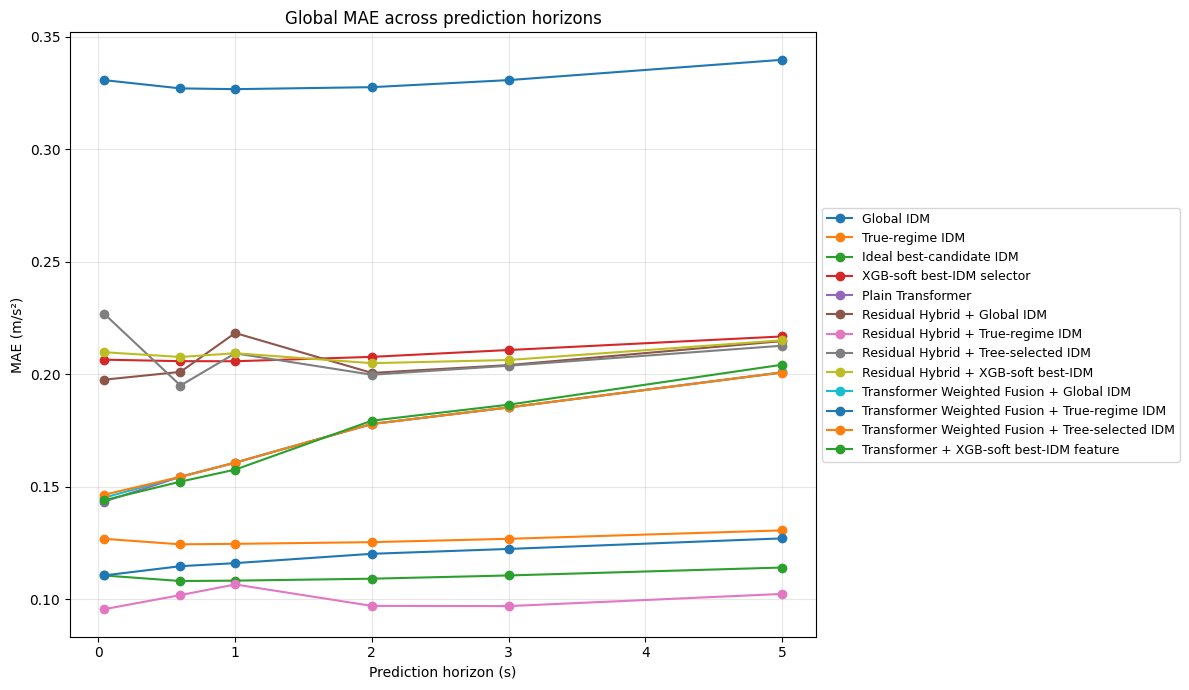

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\global_mae_by_horizon_all_models.png


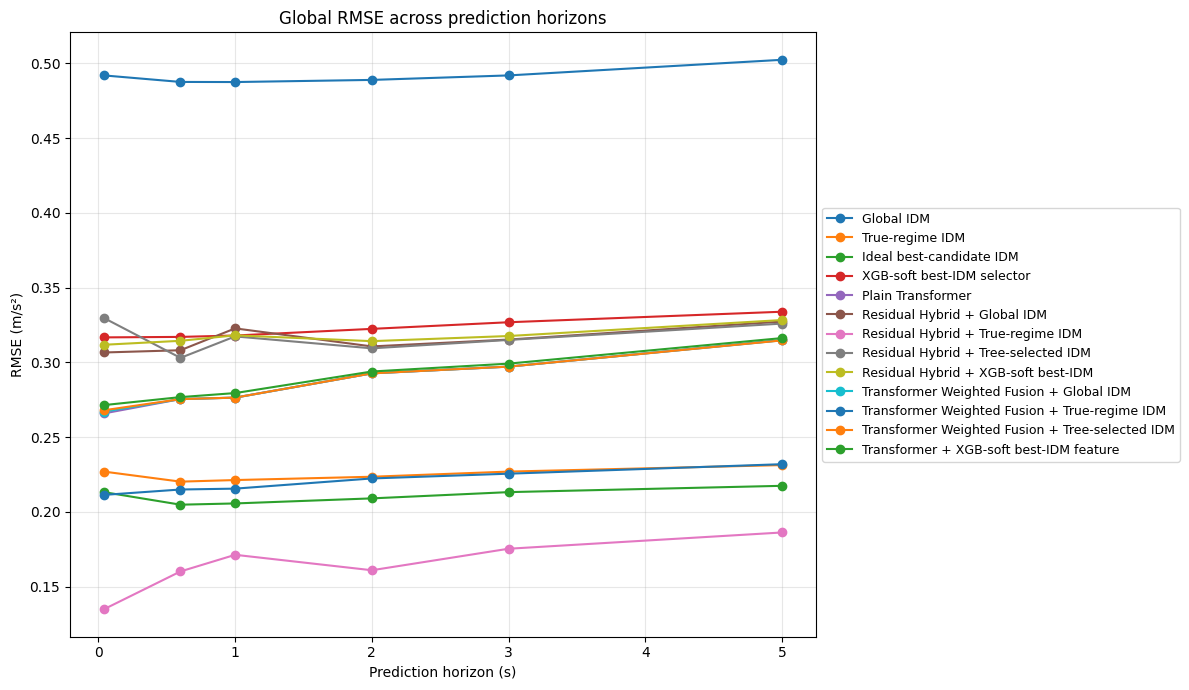

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\global_rmse_by_horizon_all_models.png


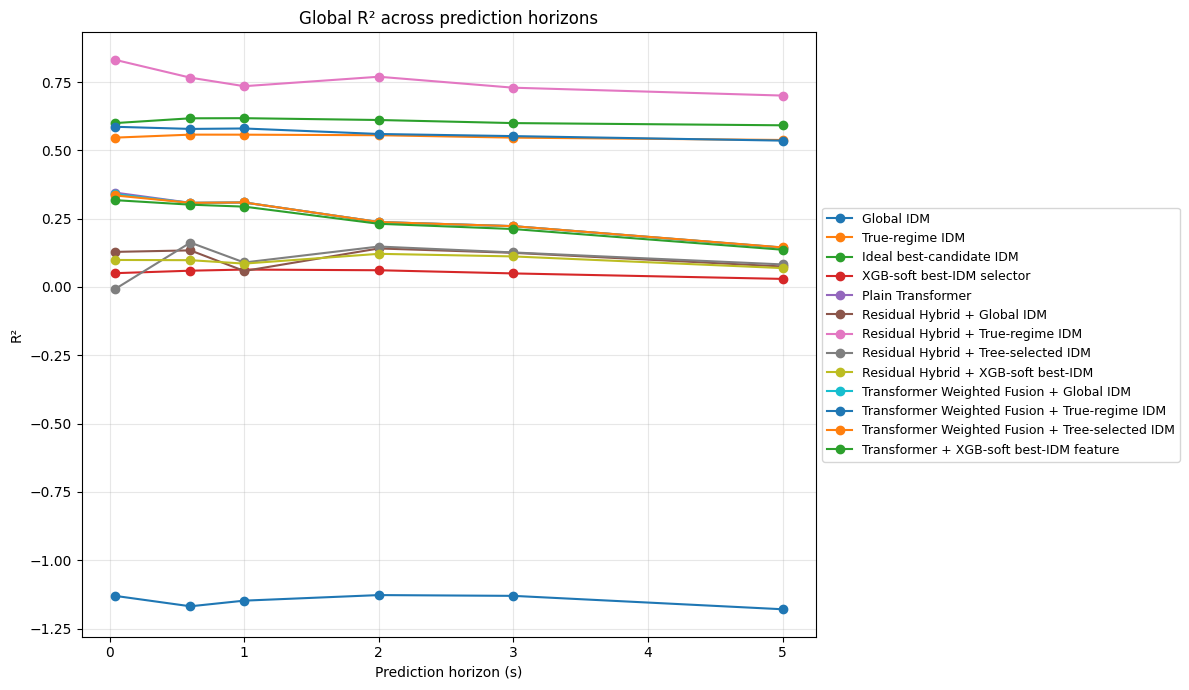

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\global_r2_by_horizon_all_models.png


In [82]:

# ============================================================
# GLOBAL COMPARISON PLOTS — SAME MODELS ACROSS HORIZONS
# ============================================================

plot_metric_over_horizon(global_metrics_df, "MAE", "Global MAE across prediction horizons", "global_mae_by_horizon_all_models.png", ylabel="MAE (m/s²)")
plot_metric_over_horizon(global_metrics_df, "RMSE", "Global RMSE across prediction horizons", "global_rmse_by_horizon_all_models.png", ylabel="RMSE (m/s²)")
plot_metric_over_horizon(global_metrics_df, "R2", "Global R² across prediction horizons", "global_r2_by_horizon_all_models.png", ylabel="R²")


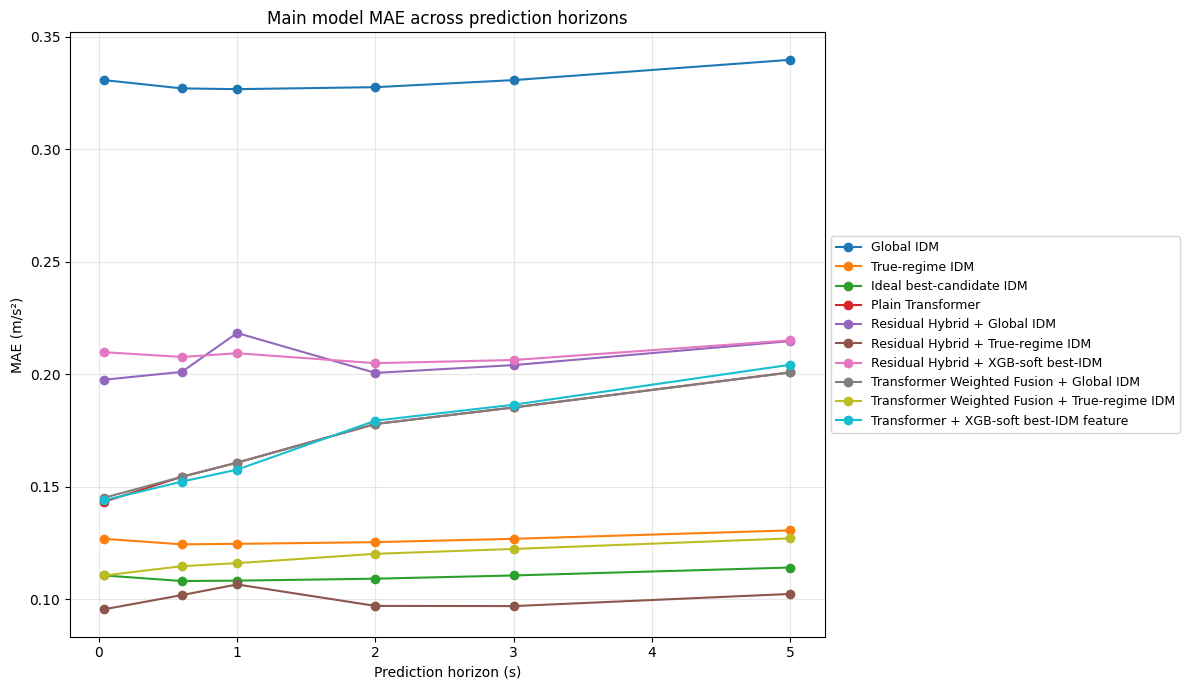

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\main_models_mae_by_horizon.png


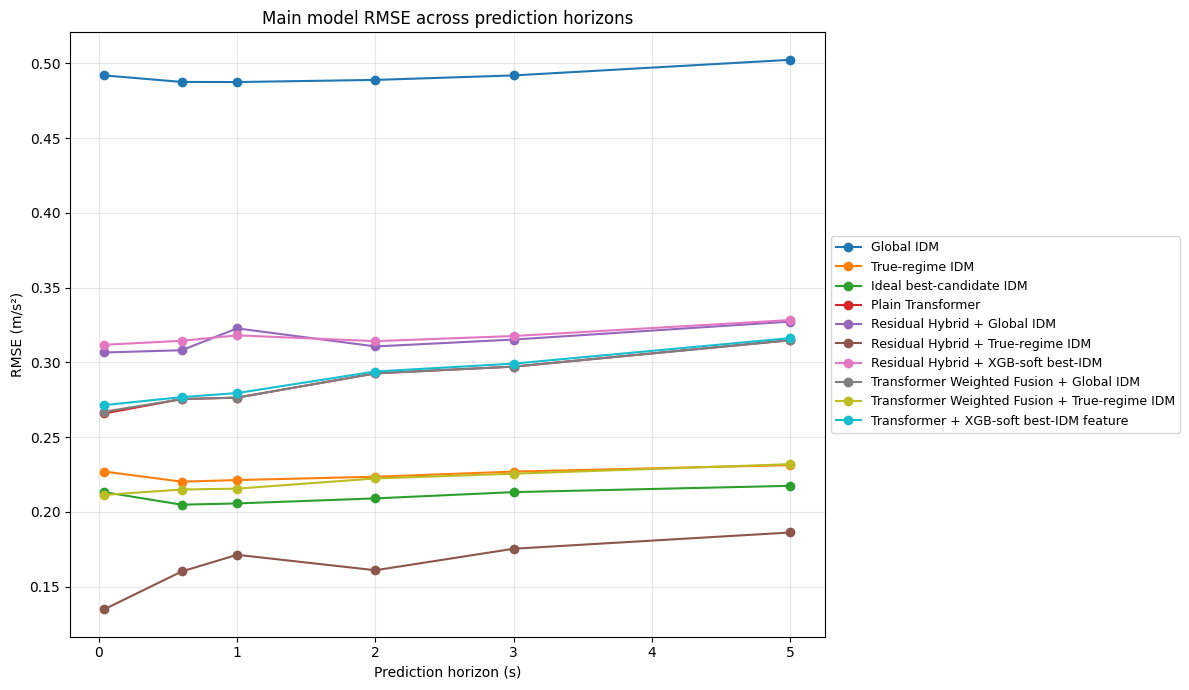

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\main_models_rmse_by_horizon.png


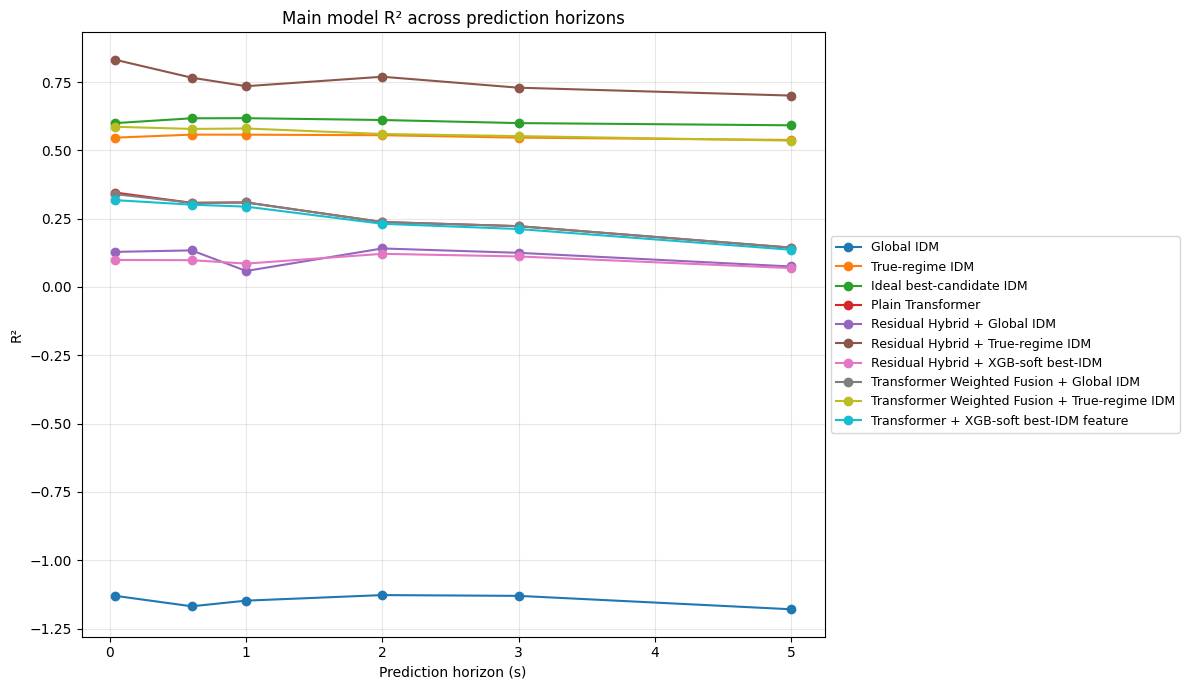

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\main_models_r2_by_horizon.png


In [83]:

# ============================================================
# CLEANER GLOBAL PLOTS — MAIN MODELS ONLY
# ============================================================

MAIN_MODELS_TO_PLOT = [
    "Global IDM",
    "True-regime IDM",
    "Ideal best-candidate IDM",
    "Plain Transformer",
    "Residual Hybrid + Global IDM",
    "Residual Hybrid + True-regime IDM",
    "Residual Hybrid + XGB-soft best-IDM",
    "Transformer Weighted Fusion + Global IDM",
    "Transformer Weighted Fusion + True-regime IDM",
    "Transformer + XGB-soft best-IDM feature",
]

plot_metric_over_horizon(global_metrics_df, "MAE", "Main model MAE across prediction horizons", "main_models_mae_by_horizon.png", model_filter=MAIN_MODELS_TO_PLOT, ylabel="MAE (m/s²)")
plot_metric_over_horizon(global_metrics_df, "RMSE", "Main model RMSE across prediction horizons", "main_models_rmse_by_horizon.png", model_filter=MAIN_MODELS_TO_PLOT, ylabel="RMSE (m/s²)")
plot_metric_over_horizon(global_metrics_df, "R2", "Main model R² across prediction horizons", "main_models_r2_by_horizon.png", model_filter=MAIN_MODELS_TO_PLOT, ylabel="R²")


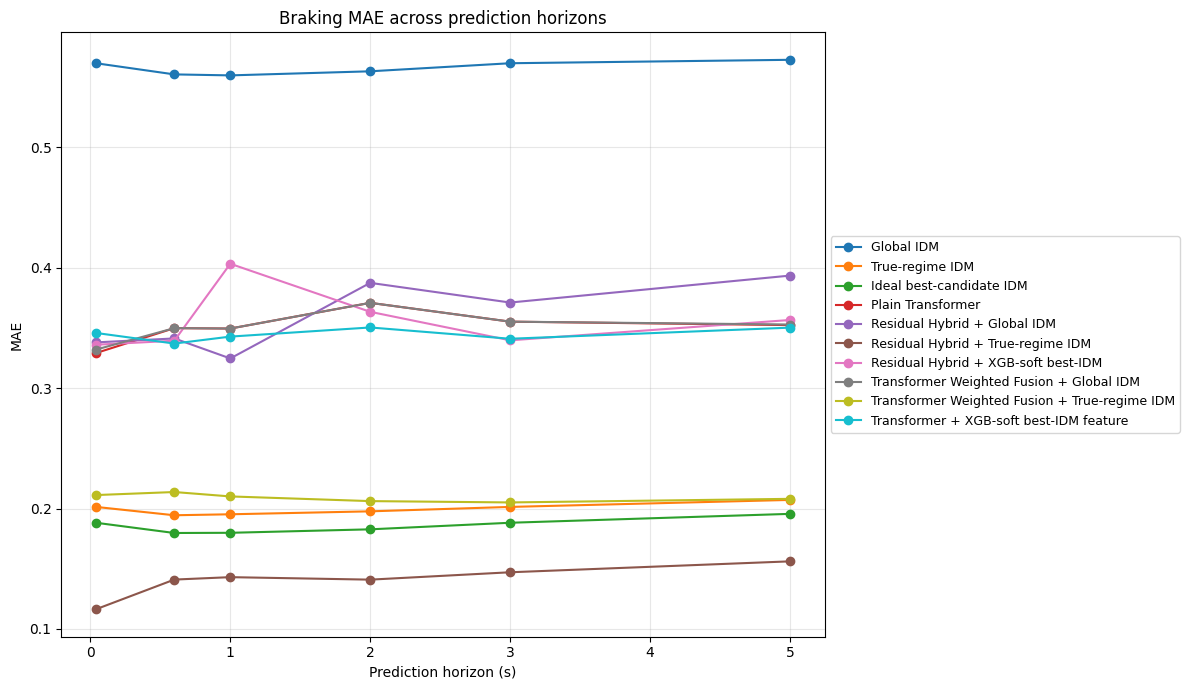

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\braking_mae_by_horizon.png


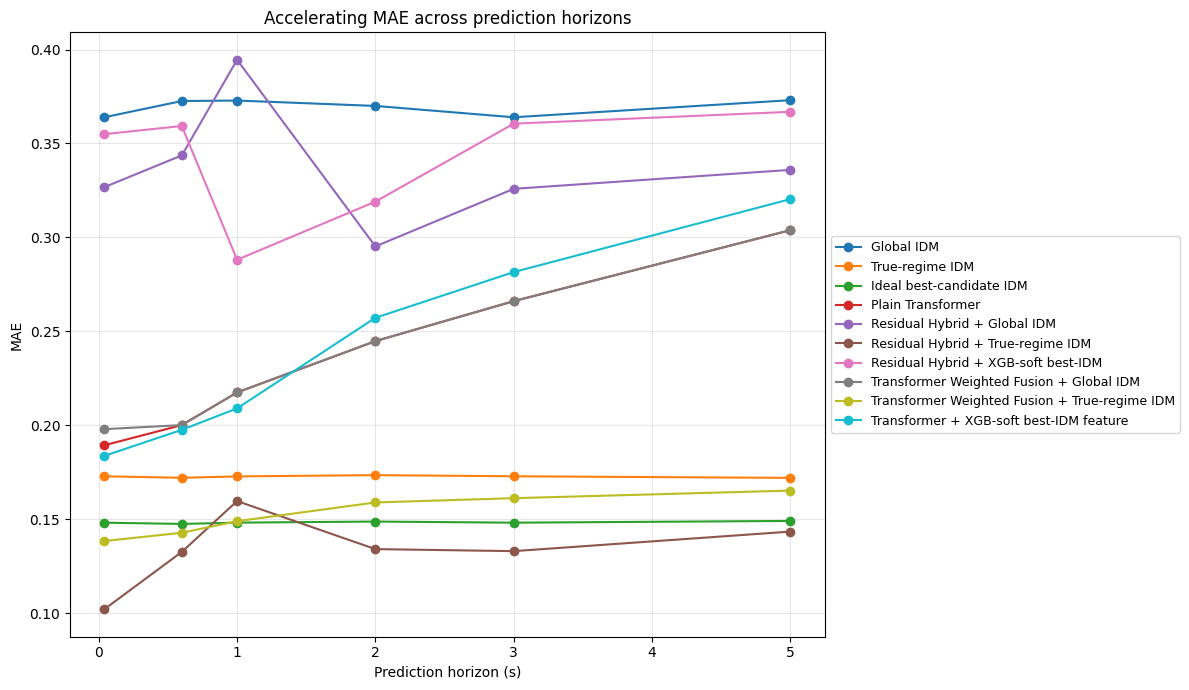

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\accelerating_mae_by_horizon.png


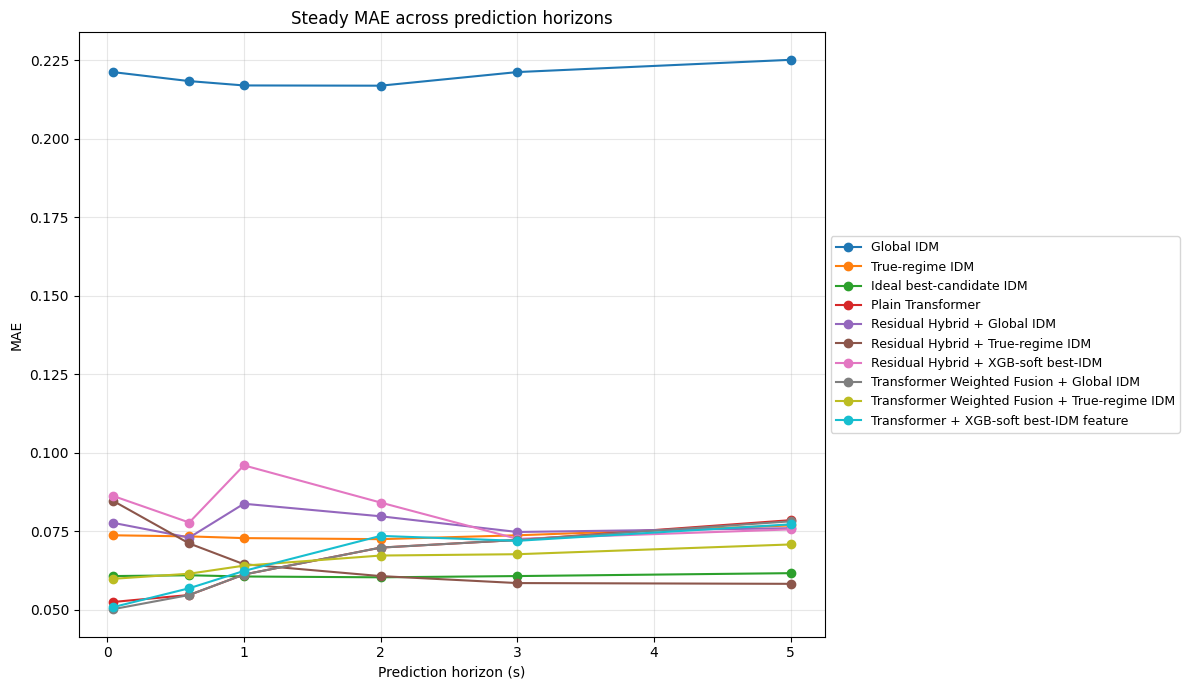

Saved: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots\steady_mae_by_horizon.png


In [84]:

# ============================================================
# REGIME-SPECIFIC PLOTS
# ============================================================

plot_regime_metric("braking", metric="MAE", model_filter=MAIN_MODELS_TO_PLOT)
plot_regime_metric("accelerating", metric="MAE", model_filter=MAIN_MODELS_TO_PLOT)
plot_regime_metric("steady", metric="MAE", model_filter=MAIN_MODELS_TO_PLOT)


In [85]:

# ============================================================
# FILES TO KEEP / ARCHIVE GUIDANCE
# ============================================================

keep_manifest = file_manifest_df.copy()
keep_manifest["KeepReason"] = np.where(
    keep_manifest["Status"].eq("FOUND"),
    "Keep selected prediction CSV: needed for horizon comparison tables and plots.",
    "Missing. Check whether this model was run for this horizon or whether the filename pattern changed.",
)

if len(extra_candidates_df) > 0:
    archive_manifest = extra_candidates_df.copy()
    archive_manifest["KeepReason"] = "Optional archive: duplicate candidate not selected for plots. Keep only if it is a deliberate alternative run."
    files_to_review_df = pd.concat([keep_manifest, archive_manifest], ignore_index=True)
else:
    files_to_review_df = keep_manifest

print("Files to keep/check/archive:")
display(files_to_review_df.sort_values(["HorizonFrames", "Model", "Status"])[["HorizonLabel", "Model", "Status", "Action", "KeepReason", "Rows", "SizeMB", "ModifiedTime", "PredictionFile"]])

keep_only_df = keep_manifest[keep_manifest["Status"] == "FOUND"].copy()
print("KEEP ONLY selected prediction files:")
display(keep_only_df.sort_values(["HorizonFrames", "Family", "Model"])[["HorizonLabel", "Model", "Family", "Type", "Rows", "PredictionFile"]])


Files to keep/check/archive:


,HorizonLabel,Model,Status,Action,KeepReason,Rows,SizeMB,ModifiedTime,PredictionFile
78,0.04s,Global IDM,DUPLICATE_CANDIDATE,ARCHIVE_OPTIONAL: duplicate candidate; selecte...,Optional archive: duplicate candidate not sele...,NaN,343.289365,2026-06-22 20:29:39.461126,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
79,0.04s,Global IDM,DUPLICATE_CANDIDATE,ARCHIVE_OPTIONAL: duplicate candidate; selecte...,Optional archive: duplicate candidate not sele...,NaN,392.809131,2026-06-19 01:20:33.829945,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
80,0.04s,Global IDM,DUPLICATE_CANDIDATE,ARCHIVE_OPTIONAL: duplicate candidate; selecte...,Optional archive: duplicate candidate not sele...,NaN,378.665489,2026-06-18 01:52:16.371142,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
81,0.04s,Global IDM,DUPLICATE_CANDIDATE,ARCHIVE_OPTIONAL: duplicate candidate; selecte...,Optional archive: duplicate candidate not sele...,NaN,238.994202,2026-06-17 09:20:20.580114,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
82,0.04s,Global IDM,DUPLICATE_CANDIDATE,ARCHIVE_OPTIONAL: duplicate candidate; selecte...,Optional archive: duplicate candidate not sele...,NaN,375.447834,2026-06-15 21:33:57.196384,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
...,...,...,...,...,...,...,...,...,...
76,5.00s,Transformer Weighted Fusion + Tree-selected IDM,FOUND,KEEP: selected prediction file for tables/plots,Keep selected prediction CSV: needed for horiz...,1257619.0,336.989048,2026-06-17 23:07:59.320311,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
75,5.00s,Transformer Weighted Fusion + True-regime IDM,FOUND,KEEP: selected prediction file for tables/plots,Keep selected prediction CSV: needed for horiz...,1257619.0,321.406436,2026-06-17 23:32:57.192590,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
124,5.00s,True-regime IDM,DUPLICATE_CANDIDATE,ARCHIVE_OPTIONAL: duplicate candidate; selecte...,Optional archive: duplicate candidate not sele...,NaN,277.807708,2026-06-17 09:20:35.496770,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
66,5.00s,True-regime IDM,FOUND,KEEP: selected prediction file for tables/plots,Keep selected prediction CSV: needed for horiz...,1257619.0,277.807708,2026-06-17 09:20:53.471227,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...


KEEP ONLY selected prediction files:


,HorizonLabel,Model,Family,Type,Rows,PredictionFile
0,0.04s,Global IDM,IDM,Deployable,1628545,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
2,0.04s,Ideal best-candidate IDM,IDM,Upper-bound,1628545,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
1,0.04s,True-regime IDM,IDM,Upper-bound,1628545,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
3,0.04s,XGB-soft best-IDM selector,IDM,Deployable,2368174,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
5,0.04s,Residual Hybrid + Global IDM,IDM-first hybrid,Deployable,2188870,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
...,...,...,...,...,...,...
69,5.00s,Plain Transformer,Transformer,Deployable,1257619,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
77,5.00s,Transformer + XGB-soft best-IDM feature,Transformer-based hybrid,Deployable,1257619,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
74,5.00s,Transformer Weighted Fusion + Global IDM,Transformer-based hybrid,Deployable,1257619,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...
76,5.00s,Transformer Weighted Fusion + Tree-selected IDM,Transformer-based hybrid,Deployable,1257619,C:\Users\ANARAMO\Documents\Tese\Tese\Tese\Hybr...


In [86]:

# ============================================================
# SAVE OUTPUTS
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

file_manifest_df.to_csv(OUTPUT_DIR / "horizon_file_keep_manifest.csv", index=False)
extra_candidates_df.to_csv(OUTPUT_DIR / "horizon_duplicate_or_extra_candidates.csv", index=False)
files_to_review_df.to_csv(OUTPUT_DIR / "horizon_files_to_keep_check_archive.csv", index=False)
row_check.to_csv(OUTPUT_DIR / "horizon_row_count_fairness_check.csv", index=False)

if len(global_metrics_df) > 0:
    global_metrics_df.to_csv(OUTPUT_DIR / "horizon_global_metrics.csv", index=False)
if len(regime_metrics_df) > 0:
    regime_metrics_df.to_csv(OUTPUT_DIR / "horizon_regime_metrics.csv", index=False)
if len(load_errors_df) > 0:
    load_errors_df.to_csv(OUTPUT_DIR / "horizon_load_errors.csv", index=False)

mae_wide.reset_index().to_csv(OUTPUT_DIR / "horizon_global_mae_wide.csv", index=False)
best_deployable.to_csv(OUTPUT_DIR / "horizon_best_deployable_by_horizon.csv", index=False)
best_upper.to_csv(OUTPUT_DIR / "horizon_best_upper_bound_by_horizon.csv", index=False)

with open(OUTPUT_DIR / "horizon_audit_config.json", "w") as f:
    json.dump({
        "PROJECT_DIR": str(PROJECT_DIR),
        "DATA_DIR": str(DATA_DIR),
        "OUTPUT_DIR": str(OUTPUT_DIR),
        "FPS": FPS,
        "HISTORY": HISTORY,
        "STRIDE": STRIDE,
        "HORIZONS": HORIZONS,
        "HORIZON_LABELS": HORIZON_LABELS,
        "BRAKE_THRESHOLD": BRAKE_THRESHOLD,
        "ACCEL_THRESHOLD": ACCEL_THRESHOLD,
        "THRESHOLD_TAG": THRESHOLD_TAG,
        "IDM_PARAM_TAG": IDM_PARAM_TAG,
        "MODEL_COUNT": len(MODEL_SPECS),
    }, f, indent=2)

print("Saved outputs to:")
print(OUTPUT_DIR)
print("Saved plots to:")
print(PLOT_DIR)


Saved outputs to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison
Saved plots to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\horizon_file_audit_and_model_comparison\plots
